In [ ]:
import pandas as pd
from pprint import pprint
from tqdm import tqdm
import json
import matplotlib.pyplot as plt

### Input to Anthroscore

In [ ]:
# anthroscore for translated (english) sentences, without "palm"
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/KI_sentences_eng_scores.csv --text_id_name id '''
terminal_input

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  --output_file generated_data/KI_sentences_eng_scores.csv --text_id_name id '

In [ ]:
# anthroscore for german sentences, without "palm"
ki_terms = open(f"config_files/ki_terms.txt", "r").read()
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/KI_sentences_ger_scores.csv --text_id_name id '''
terminal_input_ger

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities palm lms llama Transformer Sprachmodelle Sprachmodell gpt plms vortrainierte Sprachmodelle gpt-2 xlnet große Sprachmodelle llms gpt-3 Stiftungsmodell gpt-neo gpt-j chatgpt gpt-4 KI Künstliche Intelligenz ChatGPT AI Copilot Gemini Chatbot LLM Chat-GPT Sprachmodell KI-Modell KI-System KI-Tool Artificial Intelligence KI-Anwendung --output_file generated_data/KI_sentences_ger_scores.csv --text_id_name id '

In [ ]:
# anthroscore for translated (english) sentences, with "palm"
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/KI_sentences_eng_scores_palm.csv --text_id_name id '''
terminal_input

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities  --output_file generated_data/KI_sentences_eng_scores_palm.csv --text_id_name id '

In [ ]:
# anthroscore for german sentences, with "palm"
ki_terms = open(f"config_files/ki_terms.txt", "r").read()
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/KI_sentences_ger_scores_palm.csv --text_id_name id '''
terminal_input_ger

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities palm lms llama Transformer Sprachmodelle Sprachmodell gpt plms vortrainierte Sprachmodelle gpt-2 xlnet große Sprachmodelle llms gpt-3 Stiftungsmodell gpt-neo gpt-j chatgpt gpt-4 KI Künstliche Intelligenz ChatGPT AI Copilot Gemini Chatbot LLM Chat-GPT Sprachmodell KI-Modell KI-System KI-Tool Artificial Intelligence KI-Anwendung --output_file generated_data/KI_sentences_ger_scores_palm.csv --text_id_name id '

### AntroScore Results

In [ ]:
#delete duplicate sentences
text_scores = pd.read_csv(f"generated_data/KI_sentences_translated_sentence_scores_ger.csv").drop_duplicates(subset=['sentence']).reset_index(drop=True)
translated_scores =  pd.read_csv(f"generated_data/KI_sentences_translated_sentence_scores_eng.csv").drop_duplicates(subset=['sentence']).reset_index(drop=True)

ger: count    895.000000
mean       0.708351
std        1.830800
min       -6.121003
25%       -0.304033
50%        1.011808
75%        1.559317
max        7.870180
Name: anthroscore, dtype: float64
-------------------
eng: count    348.000000
mean      -0.962211
std        2.704894
min       -8.127385
25%       -3.015545
50%       -0.970741
75%        0.788488
max        9.124494
Name: anthroscore, dtype: float64


{'whiskers': [<matplotlib.lines.Line2D at 0x146c74ef0>,
 'caps': [<matplotlib.lines.Line2D at 0x146c75520>,
 'boxes': [<matplotlib.lines.Line2D at 0x146c74bc0>],
 'medians': [<matplotlib.lines.Line2D at 0x146c75ac0>],
 'fliers': [<matplotlib.lines.Line2D at 0x146c75df0>],
 'means': []}

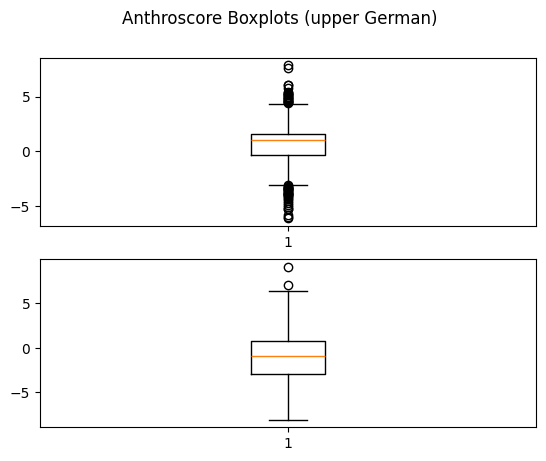

In [ ]:
# plot score distributions, compare languages
ger_results = text_scores["anthroscore"]
eng_results = translated_scores["anthroscore"]
max_len = max([len(eng_results), len(ger_results)])
print("ger:",ger_results.describe())
print("-------------------")
print("eng:",eng_results.describe())

fig, axs = plt.subplots(2)
fig.suptitle('Anthroscore Boxplots (upper German)')
axs[0].boxplot(ger_results)
axs[1].boxplot(eng_results)

In [ ]:
#print(text_scores.head())
ger_grouped = text_scores.groupby(["original_term"])
ger_mean = ger_grouped["anthroscore"].mean()

eng_grouped = translated_scores.groupby(["original_term"])
eng_mean = eng_grouped["anthroscore"].mean()

print("ger:",ger_mean)
print("-------------------")
print("eng:",eng_mean)


ger: original_term
AI                 0.591326
Artificial         0.959324
Chatbot            1.121539
Copilot            0.920569
Gemini             1.112699
Intelligenz        0.509654
KI                 0.707213
Künstliche         0.769250
Sprachmodell       0.444906
Sprachmodelle     -0.346161
Stiftungsmodell    0.332253
Transformer        0.967429
chatgpt            1.039946
gpt               -0.917521
große              0.662630
llama              1.400988
Name: anthroscore, dtype: float64
-------------------
eng: original_term
AI              0.117548
Artificial     -1.867299
Chat           -7.222070
Chatbot        -0.813953
Copilot         3.975721
Foundation     -2.408975
Gemini         -1.161637
Language       -0.503743
application    -4.736540
chatgpt        -2.651082
gpt            -1.997048
intelligence   -2.369290
large          -2.087727
llama           0.326794
model          -2.661216
models          1.448462
system         -5.179992
tool           -1.763881
transforme

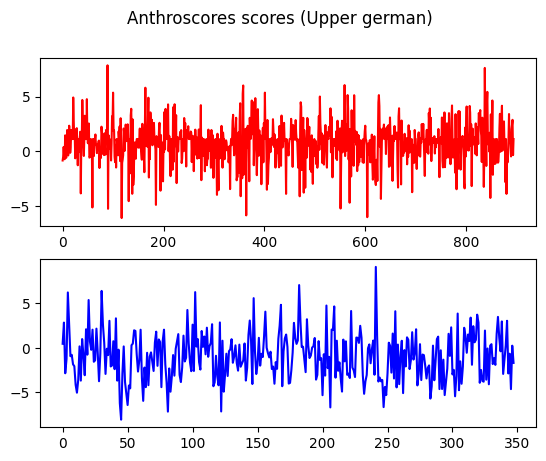

In [ ]:
fig, axs = plt.subplots(2)
fig.suptitle('Anthroscores scores (Upper german)')
axs[0].plot(ger_results, color = 'red')
axs[1].plot(eng_results, color = 'blue')